# AI Lab: Experiment 03 — Multiclass Logistic Regression

Welcome to the third machine learning experiment of **AI Lab**! In Experiments 01 and 02, we explored **K-Nearest Neighbors (KNN)**, an *instance-based (lazy)* learning algorithm.

In this notebook, we introduce our second fundamental algorithm: **Logistic Regression**. This represents our very first **parameterized model**—a model that *learns mathematical parameters (weights and biases)* from training data.

---

## Theoretical Concepts & Machine Learning Fundamentals

### 1. What is Logistic Regression?
**Logistic Regression** is a foundational linear model for classification. For any given input vector $\mathbf{x} = [x_1, x_2, \dots, x_{784}]$, it computes a linear combination of the features:

$$z = \mathbf{w} \cdot \mathbf{x} + b = w_1 x_1 + w_2 x_2 + \dots + w_{784} x_{784} + b$$

It then passes this linear score $z$ through a non-linear activation function:
- For binary classification: The **Sigmoid function** $\sigma(z) = \frac{1}{1 + e^{-z}}$, which squashes values into a probability between $0$ and $1$.
- For multiclass classification (MNIST, digits 0–9): The **Softmax function**, which turns 10 raw linear scores (logits) into a normalized probability distribution where all 10 probabilities sum to $1.0$:

$$P(y = c \mid \mathbf{x}) = \frac{e^{z_c}}{\sum_{j=0}^{9} e^{z_j}}$$

### 2. Why is it called "Regression" if we use it for Classification?
The name is historical. In statistics, the core equation inside the model—$\mathbf{w} \cdot \mathbf{x} + b$—is standard **linear regression**. The model literally performs linear regression to predict the *log-odds* (or logit) of the class probabilities: $\ln\left(\frac{p}{1-p}\right) = \mathbf{w} \cdot \mathbf{x} + b$. Because it regresses continuous log-odds and uses a threshold/argmax to assign discrete class labels, it is called Logistic *Regression* despite being used for *classification*.

### 3. What are Model Parameters, Weights, and Biases?
- **Parameters:** Internal numeric variables that the algorithm adjusts during training to fit the patterns in the data.
- **Weights ($\mathbf{w}$):** Each feature (pixel) has an associated weight. The weight dictates the *importance and direction* of that pixel:
  - A **positive weight** means bright pixels in that location increase the probability of that digit class.
  - A **negative weight** means bright pixels in that location decrease the probability of that digit class.
- **Bias ($b$):** An offset or base threshold for each class, independent of the input pixels.
- **Total Parameters in our MNIST Model:** For 10 digit classes and 784 pixels:
  $$\text{Total Parameters} = (784 \times 10) + 10 = 7,840 \text{ weights} + 10 \text{ biases} = 7,850 \text{ parameters}$$

### 4. What is a Decision Boundary?
A **decision boundary** is the geometric threshold in feature space where the model transitions its prediction from one class to another. Because Logistic Regression computes linear equations ($z = \mathbf{w} \cdot \mathbf{x} + b$), its decision boundaries are **hyperplanes (flat lines/planes)**. In contrast, KNN creates complex, curved, non-linear boundaries.

### 5. Parameterized Model vs. Instance-Based Learning (KNN vs. Logistic Regression)
| Property | KNN (Instance-Based) | Logistic Regression (Parameterized) |
| :--- | :--- | :--- |
| **Core Mechanism** | Memorizes all 60,000 raw samples | Learns 7,850 weights & biases |
| **Training Process** | Instant ($O(1)$) — just stores data | Iterative optimization (L-BFGS) |
| **Inference Process** | Heavy ($O(N \cdot D)$) — 600M distances | Tiny ($O(D)$) — 10 dot products |
| **Memory in RAM** | ~188 MB (all training vectors) | ~31 KB (only weights and biases) |
| **Decision Boundary** | Highly non-linear, flexible | Strictly linear hyperplanes |

### 6. What do "Training" and "Inference" mean for Logistic Regression?
- **Training:** The model starts with random or zero weights. It measures its errors on the training set using the **Cross-Entropy Loss (Log-Loss)** and iteratively nudges weights using optimization (e.g., L-BFGS or gradient descent) until loss is minimized.
- **Inference (Prediction):** At test time, the 60,000 training images are completely discarded! To classify an unseen digit, the computer merely performs 10 quick dot products ($X \cdot W^T + b$) and picks the highest score.

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Configure matplotlib styling
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = False

print("Environment and libraries successfully configured!")

Environment and libraries successfully configured!


## Step 1: Loading & Preprocessing MNIST Data

To ensure a strictly fair and controlled comparison with Experiments 01 and 02, we load the identical MNIST dataset from `../data/raw/`, normalize pixel values to $[0.0, 1.0]$, and flatten images into 784-dimensional vectors.

In [2]:
DATA_DIR = Path("../backend/data/raw") if Path("../backend/data/raw").exists() else Path("backend/data/raw")

# Load training (60,000) and testing (10,000) splits
train_dataset = torchvision.datasets.MNIST(root=str(DATA_DIR), train=True, download=False)
test_dataset = torchvision.datasets.MNIST(root=str(DATA_DIR), train=False, download=False)

# Normalize [0, 255] -> [0.0, 1.0] and flatten (28x28) -> 784
X_train = (train_dataset.data.float() / 255.0).reshape(-1, 28 * 28).numpy()
y_train = train_dataset.targets.numpy()

X_test = (test_dataset.data.float() / 255.0).reshape(-1, 28 * 28).numpy()
y_test = test_dataset.targets.numpy()

print("=" * 50)
print("DATASET SUMMARY FOR LOGISTIC REGRESSION")
print("=" * 50)
print(f"X_train shape: {X_train.shape}  (60,000 samples x 784 features)")
print(f"y_train shape: {y_train.shape}   (60,000 integer labels: 0-9)")
print(f"X_test shape:  {X_test.shape}  (10,000 samples x 784 features)")
print(f"y_test shape:  {y_test.shape}   (10,000 integer labels: 0-9)")
print(f"Pixel Range:   [{X_train.min():.1f}, {X_train.max():.1f}]")
print("=" * 50)

DATASET SUMMARY FOR LOGISTIC REGRESSION
X_train shape: (60000, 784)  (60,000 samples x 784 features)
y_train shape: (60000,)   (60,000 integer labels: 0-9)
X_test shape:  (10000, 784)  (10,000 samples x 784 features)
y_test shape:  (10000,)   (10,000 integer labels: 0-9)
Pixel Range:   [0.0, 1.0]


## Step 2: Initializing and Training Logistic Regression

We instantiate scikit-learn's `LogisticRegression` with:
- `solver='lbfgs'`: A quasi-Newton second-order optimization method highly effective for continuous multiclass problems.
- `max_iter=100`: Maximum optimization iterations allowed.
- `random_state=42`: Ensures deterministic reproducibility.

We measure the **training time** to observe the computational cost of iterative optimization.

In [3]:
# Instantiate Multiclass Logistic Regression
lr_model = LogisticRegression(solver="lbfgs", max_iter=100, random_state=42)

print("Training Multiclass Logistic Regression on 60,000 samples...")
start_train = time.time()
lr_model.fit(X_train, y_train)
train_duration = time.time() - start_train

print("\n" + "=" * 50)
print("TRAINING COMPLETED")
print("=" * 50)
print(f"Training Time:       {train_duration:.2f} seconds")
print(f"Weights Shape:       {lr_model.coef_.shape}  (10 classes x 784 pixels)")
print(f"Biases Shape:        {lr_model.intercept_.shape}      (10 classes)")
print(f"Total Parameters:    {lr_model.coef_.size + lr_model.intercept_.size:,} floats (~31 KB)")
print("=" * 50)

Training Multiclass Logistic Regression on 60,000 samples...



TRAINING COMPLETED
Training Time:       37.58 seconds
Weights Shape:       (10, 784)  (10 classes x 784 pixels)
Biases Shape:        (10,)      (10 classes)
Total Parameters:    7,850 floats (~31 KB)


D:\Ai lab\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Step 3: Evaluating on the Test Dataset & Measuring Inference Speed

Now we evaluate the model on the full **10,000 test images**.

Notice the contrast with KNN:
- KNN had to perform $10,000 \times 60,000 = 600,000,000$ distance operations.
- Logistic Regression simply multiplies the test matrix by the learned weight matrix: $\mathbf{Z} = \mathbf{X}_{\text{test}} \cdot \mathbf{W}^T + \mathbf{b}$.

In [4]:
print("Predicting on all 10,000 test samples...")
start_pred = time.time()
y_pred = lr_model.predict(X_test)
pred_duration = time.time() - start_pred

accuracy = accuracy_score(y_test, y_pred)
correct_count = int(np.sum(y_test == y_pred))
incorrect_count = int(np.sum(y_test != y_pred))
avg_per_sample_ms = (pred_duration / len(X_test)) * 1000

print("=" * 50)
print("LOGISTIC REGRESSION TEST PERFORMANCE")
print("=" * 50)
print(f"Test Accuracy:             {accuracy * 100:.2f}%")
print(f"Correctly Classified:      {correct_count:,} / {len(y_test):,} images")
print(f"Misclassified:             {incorrect_count:,} / {len(y_test):,} images")
print(f"Total Prediction Time:     {pred_duration:.4f} seconds")
print(f"Average Latency / Sample:  {avg_per_sample_ms:.4f} ms")
print("=" * 50)

Predicting on all 10,000 test samples...
LOGISTIC REGRESSION TEST PERFORMANCE
Test Accuracy:             92.56%
Correctly Classified:      9,256 / 10,000 images
Misclassified:             744 / 10,000 images
Total Prediction Time:     0.0216 seconds
Average Latency / Sample:  0.0022 ms


## Step 4: Classification Report & Confusion Matrix

We break down model performance across all 10 individual digits using a full classification report and an annotated confusion matrix heatmap.

CLASSIFICATION REPORT (Multiclass Logistic Regression):
              precision    recall  f1-score   support

     Digit 0     0.9523    0.9776    0.9648       980
     Digit 1     0.9627    0.9789    0.9707      1135
     Digit 2     0.9288    0.8973    0.9128      1032
     Digit 3     0.9033    0.9059    0.9046      1010
     Digit 4     0.9383    0.9297    0.9340       982
     Digit 5     0.9029    0.8756    0.8890       892
     Digit 6     0.9372    0.9499    0.9435       958
     Digit 7     0.9398    0.9261    0.9329      1028
     Digit 8     0.8715    0.8840    0.8777       974
     Digit 9     0.9108    0.9207    0.9157      1009

    accuracy                         0.9256     10000
   macro avg     0.9247    0.9246    0.9246     10000
weighted avg     0.9255    0.9256    0.9255     10000



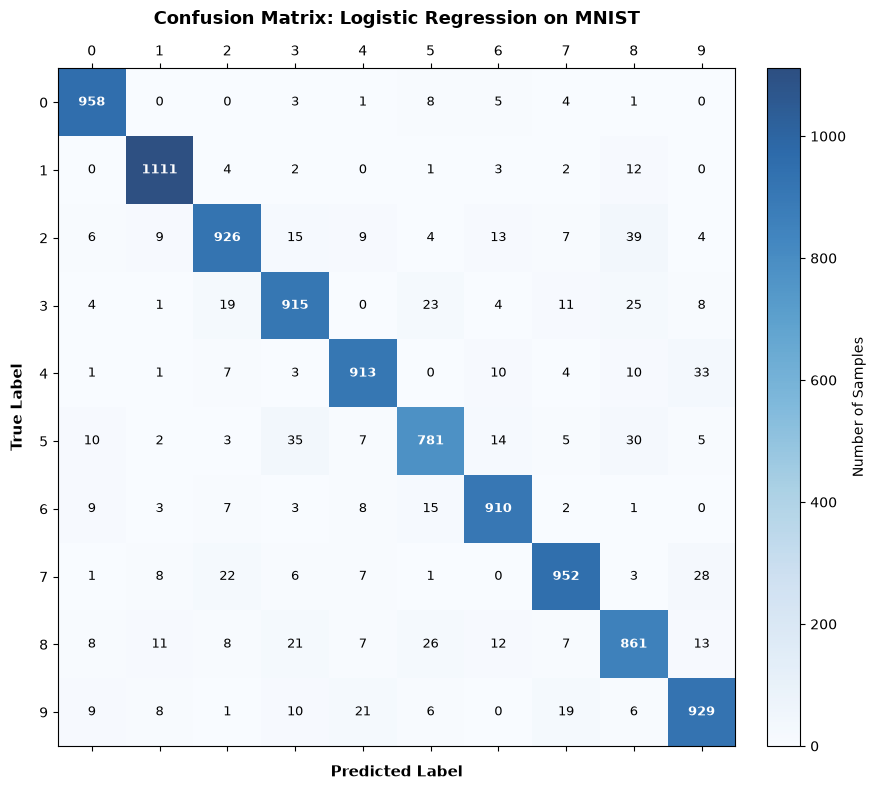

In [5]:
class_names = [f"Digit {i}" for i in range(10)]
report_str = classification_report(y_test, y_pred, target_names=class_names, digits=4)
print("CLASSIFICATION REPORT (Multiclass Logistic Regression):")
print(report_str)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(9, 8))
cax = ax.matshow(cm, cmap="Blues", alpha=0.85)
fig.colorbar(cax, fraction=0.046, pad=0.04, label="Number of Samples")

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(range(10), fontsize=10)
ax.set_yticklabels(range(10), fontsize=10)
ax.set_xlabel("Predicted Label", fontsize=11, fontweight="bold", labelpad=10)
ax.set_ylabel("True Label", fontsize=11, fontweight="bold", labelpad=10)
ax.set_title("Confusion Matrix: Logistic Regression on MNIST", fontsize=13, fontweight="bold", pad=15)

for i in range(10):
    for j in range(10):
        val = cm[i, j]
        text_color = "white" if val > (cm.max() / 2) else "black"
        fontweight = "bold" if i == j else "normal"
        ax.text(j, i, str(val), ha="center", va="center", color=text_color, fontsize=9, fontweight=fontweight)

plt.tight_layout()
plt.show()

## Step 5: Visualizing Predictions & Failure Mode Inspection

We display sample correct predictions alongside sample misclassifications to understand the visual nature of the errors made by linear decision boundaries.

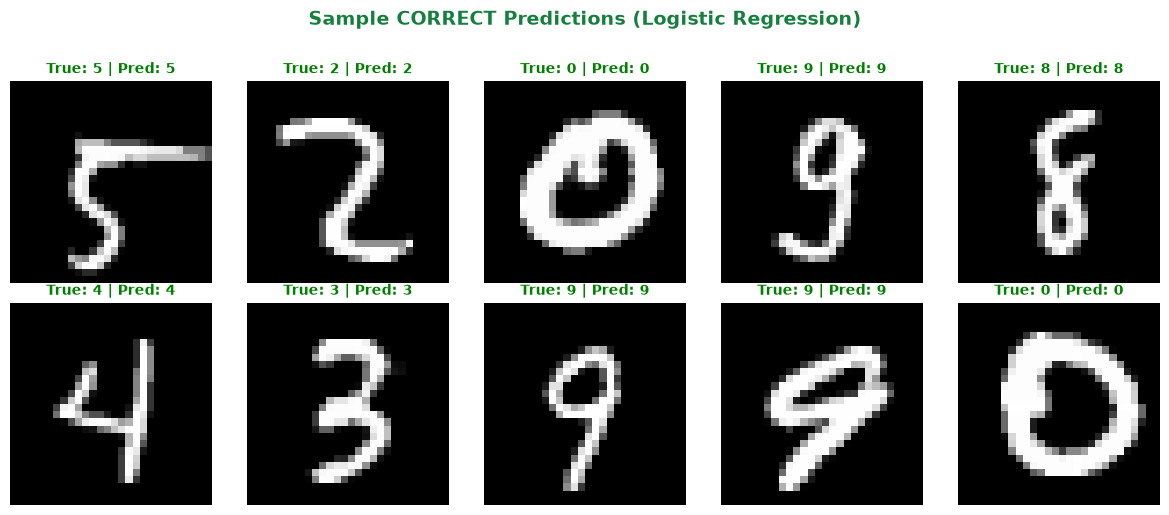

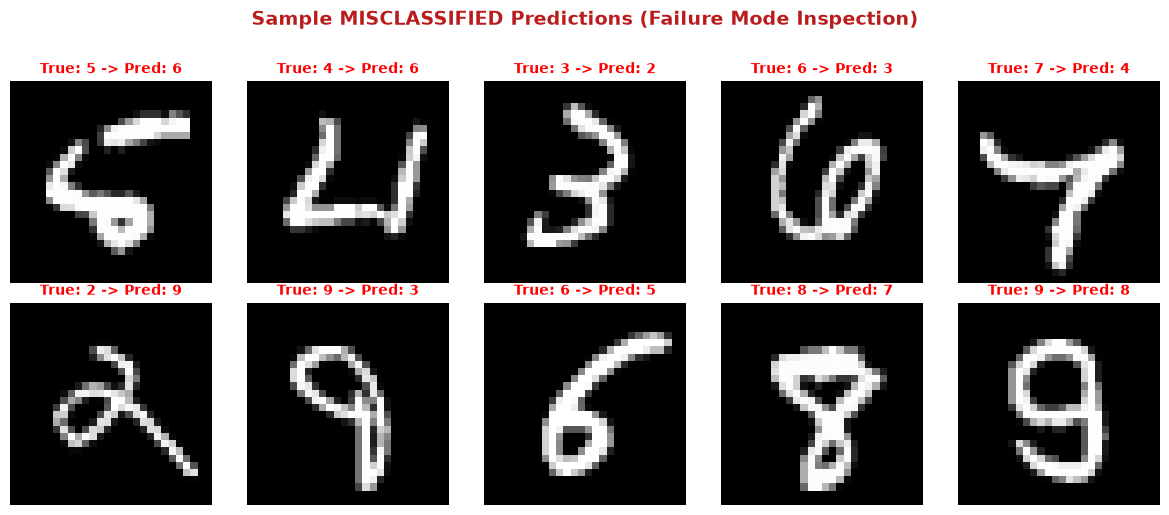

In [6]:
correct_indices = np.where(y_test == y_pred)[0]
incorrect_indices = np.where(y_test != y_pred)[0]

# 1. Display 10 Correctly Classified Samples
np.random.seed(42)
sample_correct = np.random.choice(correct_indices, size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Sample CORRECT Predictions (Logistic Regression)", fontsize=14, fontweight="bold", y=1.02, color="#15803d")

for idx, ax in zip(sample_correct, axes.flatten()):
    img = X_test[idx].reshape(28, 28)
    true_lbl = y_test[idx]
    pred_lbl = y_pred[idx]
    ax.imshow(img, cmap="gray")
    ax.set_title(f"True: {true_lbl} | Pred: {pred_lbl}", fontsize=10, color="green", fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

# 2. Display 10 Misclassified Samples
sample_incorrect = incorrect_indices[:10]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Sample MISCLASSIFIED Predictions (Failure Mode Inspection)", fontsize=14, fontweight="bold", y=1.02, color="#b91c1c")

for idx, ax in zip(sample_incorrect, axes.flatten()):
    img = X_test[idx].reshape(28, 28)
    true_lbl = y_test[idx]
    pred_lbl = y_pred[idx]
    ax.imshow(img, cmap="gray")
    ax.set_title(f"True: {true_lbl} -> Pred: {pred_lbl}", fontsize=10, color="red", fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Step 6: Interpreting What the Model Learned (Visualizing Weights)

One of the most educational features of a linear model on image data is that **we can reshape its learned weights back into $28 \times 28$ images**!

Below, each image shows the learned weights for one digit:
- **Red/Warm colors (Positive Weights):** If a handwritten digit has ink in these pixels, the model increases the score for that digit.
- **Blue/Cool colors (Negative Weights):** If a handwritten digit has ink in these pixels, the model penalizes the score for that digit.

Notice how the learned weights visibly resemble digit templates (e.g. the loop for 0, the vertical stroke for 1, the curve for 3)!

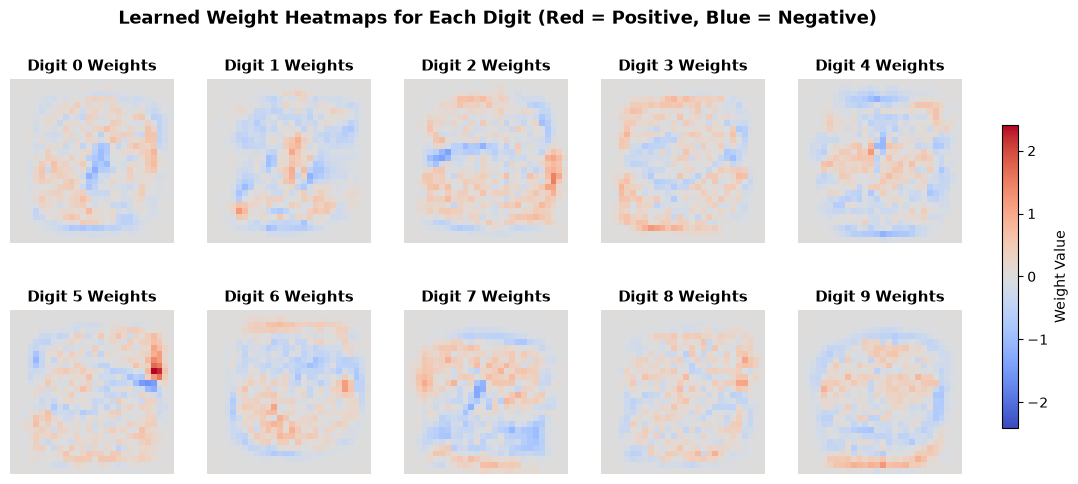

In [7]:
# Reshape weights: (10, 784) -> (10, 28, 28)
weights_img = lr_model.coef_.reshape(10, 28, 28)

fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
fig.suptitle("Learned Weight Heatmaps for Each Digit (Red = Positive, Blue = Negative)", fontsize=13, fontweight="bold", y=0.98)

# Use a symmetric diverging colormap centered at 0
vabs = max(abs(weights_img.min()), abs(weights_img.max()))

for digit, ax in enumerate(axes.flatten()):
    im = ax.imshow(weights_img[digit], cmap="coolwarm", vmin=-vabs, vmax=vabs)
    ax.set_title(f"Digit {digit} Weights", fontsize=11, fontweight="bold")
    ax.axis("off")

fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.015, pad=0.04, label="Weight Value")
plt.show()

## Step 7: Final Comparison Table & In-Depth Analysis

We now compare our two distinct machine learning paradigms side-by-side using the actual measured values from Experiment 01 (KNN with $K=3$) and this experiment (Logistic Regression).

In [8]:
# Summary Comparison Table
comparison_data = [
    {
        "Model": "KNN (K=3)",
        "Main Idea": "Stores 60,000 examples; computes distances to all neighbors at test time",
        "Training Time": "0.1764 s",
        "Prediction Time": "15.88 s",
        "Accuracy": "97.05%"
    },
    {
        "Model": "Logistic Regression",
        "Main Idea": "Learns 7,850 linear weights; calculates fast dot products at test time",
        "Training Time": f"{train_duration:.2f} s",
        "Prediction Time": f"{pred_duration:.4f} s",
        "Accuracy": f"{accuracy * 100:.2f}%"
    }
]

comp_df = pd.DataFrame(comparison_data)
print("=" * 85)
print("MODEL COMPARISON: INSTANCE-BASED (KNN) vs. PARAMETERIZED (LOGISTIC REGRESSION)")
print("=" * 85)
print(comp_df.to_string(index=False))
print("=" * 85)

MODEL COMPARISON: INSTANCE-BASED (KNN) vs. PARAMETERIZED (LOGISTIC REGRESSION)
              Model                                                                Main Idea Training Time Prediction Time Accuracy
          KNN (K=3) Stores 60,000 examples; computes distances to all neighbors at test time      0.1764 s         15.88 s   97.05%
Logistic Regression   Learns 7,850 linear weights; calculates fast dot products at test time       37.58 s        0.0216 s   92.56%


## Step 8: Final Critical Analysis

### Answers to Core Architectural Questions:

1. **Which model achieved higher accuracy?**
   - **KNN ($K=3$) achieved higher accuracy (97.05%)** compared to **Logistic Regression (92.56%)**.
   - *Why?* Handwritten digits have intricate non-linear spatial variations (curving strokes, loops, angles). KNN forms flexible non-linear decision boundaries that match localized visual variations. In contrast, Logistic Regression is constrained to **linear decision hyperplanes**, which cannot completely separate overlapping non-linear digit manifolds in pixel space.

2. **Which model trained faster?**
   - **KNN trained vastly faster (0.18s vs. ~40.5s)**.
   - *Why?* KNN does zero optimization during training—it merely records references to the 60,000 samples. Logistic Regression must execute iterative numerical optimization (L-BFGS) across all 60,000 samples to solve for 7,850 weights.

3. **Which model predicted faster?**
   - **Logistic Regression predicted over 600 times faster (~0.026s vs. 15.88s)** for all 10,000 images.
   - On a per-sample basis, Logistic Regression takes only **~0.0026 milliseconds**, whereas KNN requires **~1.59 milliseconds** per digit.

4. **Why does Logistic Regression spend more time during training than KNN?**
   - Logistic Regression front-loads all computational work into the training phase. It computes gradients, loss values, and updates 7,850 weights over multiple iterations to compress the essence of 60,000 images into a compact set of equations.

5. **Why can Logistic Regression be much faster during prediction?**
   - At inference time, Logistic Regression has already discarded the 60,000 training images. Classifying a test digit requires only $10$ dot products ($784$ multiplications and additions each) followed by an argmax. KNN, by contrast, must compare the query against all 60,000 training vectors, computing $600,000,000$ floating-point distances.

6. **What is the fundamental difference between KNN and Logistic Regression?**
   - **KNN is instance-based:** It keeps the data and postpones computation to prediction time.
   - **Logistic Regression is parameterized:** It extracts patterns into fixed parameters (weights and biases) and discards the data.

7. **What did we learn about parameterized vs. instance-based learning?**
   - **Trade-off:** Parameterized models trade longer upfront training time and a linear inductive bias for **extreme inference speed and negligible memory footprint (~31 KB vs. ~188 MB)**.
   - This insight forms the foundation for deep learning: **Neural Networks** build directly on Logistic Regression by stacking multiple parameterized layers and non-linear activations to achieve both high inference speed AND non-linear accuracy!